# SIT720 8.1D - Machine Learning Mini Project
## Sydney Housing Price Prediction and Decision Support System

**Student:** Zenith Anthony  
**Student ID:** s225534396

This notebook implements the complete modelling workflow for the Distinction task: data quality checks, exploratory analysis, feature engineering, three regression approaches, training-only cross-validation and tuning, held-out test evaluation, error analysis, an LLM/manual valuation comparison, and export of the final model for deployment.

**Data source.** 105 sold-property records were manually transcribed from publicly available Realestate.com.au sold-listing pages: 35 each from Bondi Beach, Parramatta and Blacktown. The CSV included with this submission records the source page for every row.

In [1]:
from pathlib import Path
import json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

ROOT = Path('.')
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)
DATA = ROOT / 'sydney_housing_sold_105.csv'
pd.set_option('display.max_columns', 30)

## Part 1 - Problem definition and data quality

The target is **sold price (AUD)**. I selected Bondi Beach, Parramatta and Blacktown because they represent clearly different Sydney housing markets in this collected sample: Bondi Beach is a premium coastal market, Parramatta is a major western employment/transport centre with mixed houses and townhouses, and Blacktown is a lower-priced western suburban market. This gives the model meaningful variation rather than concentrating on one price segment.

The main limitations are that the dataset is manually collected, relatively small, not a random sample of all sales, and several listing fields such as parking and land size are missing. Exact renovation quality, view, street position, zoning, floor area and agent description were not consistently available in the summary listings. These omissions can cause large errors, especially for unusual premium properties.

In [2]:
df = pd.read_csv(DATA, parse_dates=['sale_date'])
print('Shape:', df.shape)
print()
print('Rows by suburb:')
print(df.groupby('suburb').size())
print()
print('Missing values:')
print(df.isna().sum())
print()
print('Date range:', df['sale_date'].min().date(), 'to', df['sale_date'].max().date())
display(df.head())

Shape: (105, 10)

Rows by suburb:
suburb
Blacktown      35
Bondi Beach    35
Parramatta     35
dtype: int64

Missing values:
suburb            0
address           0
sale_price        0
bedrooms          0
bathrooms         0
parking          13
land_size_m2     38
property_type     0
sale_date         0
source_page       0
dtype: int64

Date range: 2020-11-28 to 2026-09-17


,suburb,address,sale_price,bedrooms,bathrooms,parking,land_size_m2,property_type,sale_date,source_page
0,Bondi Beach,33 Wellington Street,3620000,4,3,NaN,NaN,House,2026-09-12,https://www.realestate.com.au/sold/property-ho...
1,Bondi Beach,22 Chambers Avenue,3700000,3,1,1.0,223.0,House,2026-06-01,https://www.realestate.com.au/sold/property-ho...
2,Bondi Beach,4/22-28 O'Brien Street,1670000,2,2,1.0,NaN,Other,2026-05-13,https://www.realestate.com.au/sold/property-ho...
3,Bondi Beach,9 Cox Avenue,4153000,4,2,NaN,220.7,House,2026-05-09,https://www.realestate.com.au/sold/property-ho...
4,Bondi Beach,5/3-5 Hastings Parade,1085000,2,1,NaN,NaN,Other,2026-03-10,https://www.realestate.com.au/sold/property-ho...


In [3]:
summary = df.groupby('suburb')['sale_price'].agg(['count','median','mean','min','max'])
summary.style.format({'median':'A${:,.0f}','mean':'A${:,.0f}','min':'A${:,.0f}','max':'A${:,.0f}'})

,count,median,mean,min,max
suburb,,,,,
Blacktown,35,"A$1,080,000","A$1,149,086","A$820,000","A$1,900,000"
Bondi Beach,35,"A$4,105,000","A$4,170,230","A$840,000","A$9,400,000"
Parramatta,35,"A$1,250,000","A$1,329,368","A$720,000","A$2,300,000"


## Part 2 - Data understanding and feature engineering

Before engineering features, my expected three strongest variables are **suburb**, **property type**, and **bedrooms**. Suburb represents location/market segment, property type distinguishes houses from attached dwellings, and bedroom count is a simple proxy for usable size. Land size is also important, but it is missing for many records and therefore was not selected in the initial top three.

I use median imputation for numeric missing values because property attributes can be skewed by unusually large homes and median imputation is robust to those extremes. Categorical variables are imputed with the most frequent category and one-hot encoded.

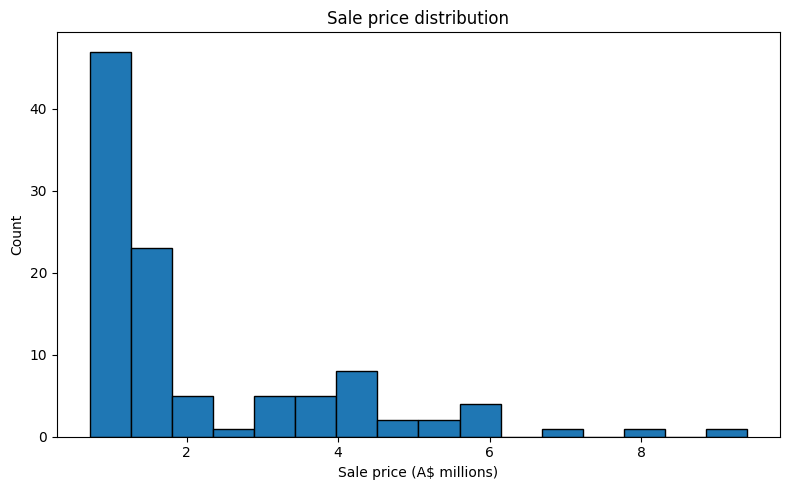

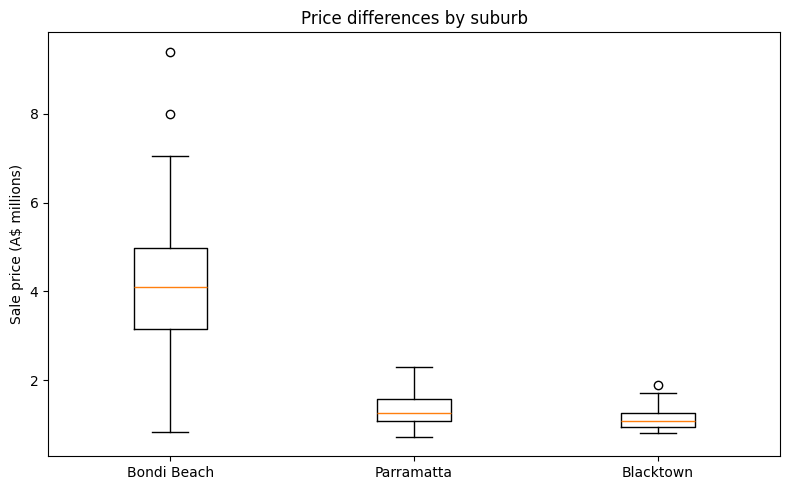

In [4]:
plt.figure(figsize=(8,5))
plt.hist(df['sale_price']/1e6, bins=16, edgecolor='black')
plt.xlabel('Sale price (A$ millions)'); plt.ylabel('Count'); plt.title('Sale price distribution')
plt.tight_layout(); plt.show()

subs=['Bondi Beach','Parramatta','Blacktown']
plt.figure(figsize=(8,5))
plt.boxplot([df.loc[df.suburb==s,'sale_price']/1e6 for s in subs], tick_labels=subs, showfliers=True)
plt.ylabel('Sale price (A$ millions)'); plt.title('Price differences by suburb')
plt.tight_layout(); plt.show()

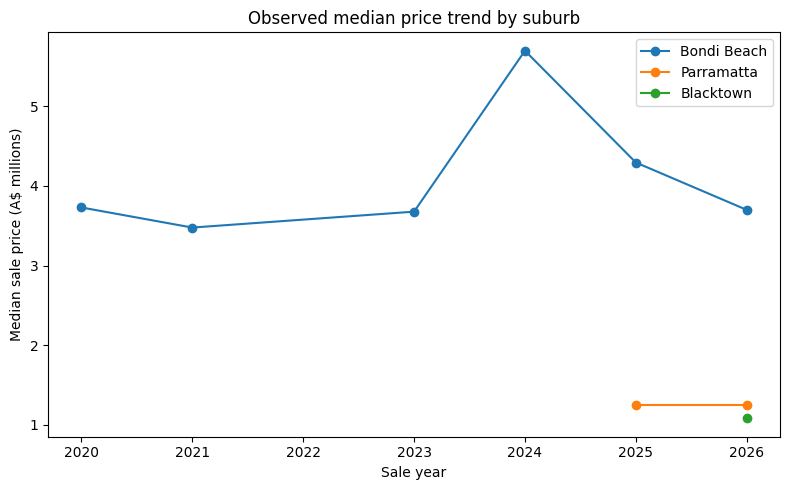

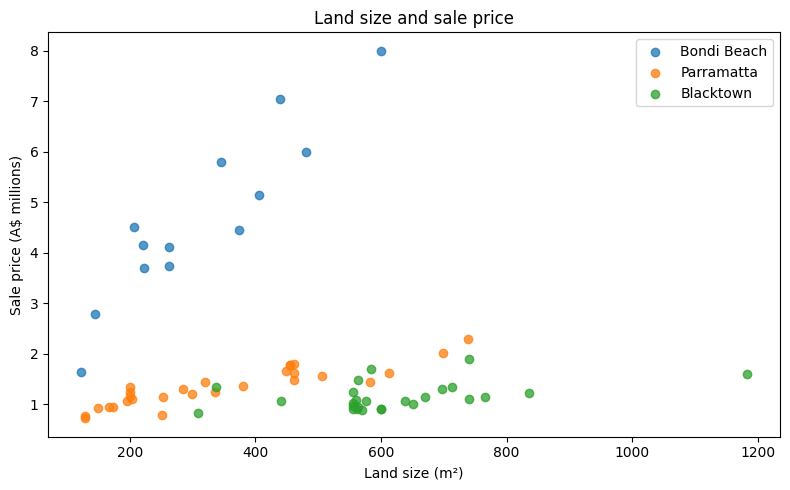

In [5]:
trend = (df.assign(sale_year=df['sale_date'].dt.year)
           .groupby(['sale_year','suburb'])['sale_price'].median().reset_index())
plt.figure(figsize=(8,5))
for s in subs:
    t=trend[trend.suburb==s]
    plt.plot(t.sale_year, t.sale_price/1e6, marker='o', label=s)
plt.xlabel('Sale year'); plt.ylabel('Median sale price (A$ millions)')
plt.title('Observed median price trend by suburb'); plt.legend(); plt.tight_layout(); plt.show()

plotdf=df.dropna(subset=['land_size_m2'])
plt.figure(figsize=(8,5))
for s in subs:
    t=plotdf[plotdf.suburb==s]
    plt.scatter(t.land_size_m2, t.sale_price/1e6, label=s, alpha=.75)
plt.xlabel('Land size (m²)'); plt.ylabel('Sale price (A$ millions)')
plt.title('Land size and sale price'); plt.legend(); plt.tight_layout(); plt.show()

In [6]:
def engineer(frame):
    x=frame.copy()
    x['sale_date']=pd.to_datetime(x['sale_date'])
    x['sale_year']=x['sale_date'].dt.year
    x['sale_month']=x['sale_date'].dt.month
    x['sale_quarter']=x['sale_date'].dt.quarter.astype(str)
    x['bed_bath_total']=x['bedrooms']+x['bathrooms']
    x['land_per_bed']=x['land_size_m2']/x['bedrooms'].replace(0,np.nan)
    x['parking_per_bed']=x['parking']/x['bedrooms'].replace(0,np.nan)
    return x

dfe=engineer(df)
features=['suburb','property_type','bedrooms','bathrooms','parking','land_size_m2',
          'sale_year','sale_month','sale_quarter','bed_bath_total','land_per_bed','parking_per_bed']
display(dfe[features+['sale_price']].head())

,suburb,property_type,bedrooms,bathrooms,parking,land_size_m2,sale_year,sale_month,sale_quarter,bed_bath_total,land_per_bed,parking_per_bed,sale_price
0,Bondi Beach,House,4,3,NaN,NaN,2026,9,3,7,NaN,NaN,3620000
1,Bondi Beach,House,3,1,1.0,223.0,2026,6,2,4,74.333333,0.333333,3700000
2,Bondi Beach,Other,2,2,1.0,NaN,2026,5,2,4,NaN,0.500000,1670000
3,Bondi Beach,House,4,2,NaN,220.7,2026,5,2,6,55.175000,NaN,4153000
4,Bondi Beach,Other,2,1,NaN,NaN,2026,3,1,3,NaN,NaN,1085000


The engineered variables retain the original features but add time indicators and ratios. `bed_bath_total` represents dwelling capacity; `land_per_bed` separates large blocks from compact dwellings with the same bedroom count; and `parking_per_bed` adds a rough amenity/space measure. These choices are consistent with the initial expectation that location, dwelling type and dwelling size drive price.

## Part 3 - Model development and evaluation

I compare three modelling approaches:

1. **Ridge regression** - interpretable linear baseline with L2 regularisation. It may underfit nonlinear price relationships but should be stable on a small dataset.
2. **Random forest regression** - nonlinear bagging ensemble that can capture interactions such as suburb × size and is robust to outliers. I expect it to perform best or close to best.
3. **Gradient boosting regression** - sequential tree ensemble that can model nonlinear effects efficiently, but may overfit if depth or learning rate is too high.

The held-out 20% test set is created once and not used for tuning. Hyperparameters are chosen only with 5-fold cross-validation on the training data. The folds are stratified by suburb so each validation fold contains all three markets.

In [7]:
X=dfe[features]
y=dfe['sale_price']
idx_train, idx_test = train_test_split(np.arange(len(dfe)), test_size=0.20, random_state=42, stratify=dfe['suburb'])
X_train=X.iloc[idx_train].reset_index(drop=True); y_train=y.iloc[idx_train].reset_index(drop=True)
X_test=X.iloc[idx_test].reset_index(drop=True); y_test=y.iloc[idx_test].reset_index(drop=True)
meta_train=dfe.iloc[idx_train].reset_index(drop=True); meta_test=dfe.iloc[idx_test].reset_index(drop=True)
print('Train:', len(X_train), 'Test:', len(X_test))
print('Test suburb counts:')
print(meta_test['suburb'].value_counts())

Train: 84 Test: 21
Test suburb counts:
suburb
Parramatta     7
Bondi Beach    7
Blacktown      7
Name: count, dtype: int64


In [8]:
num_cols=['bedrooms','bathrooms','parking','land_size_m2','sale_year','sale_month','bed_bath_total','land_per_bed','parking_per_bed']
cat_cols=['suburb','property_type','sale_quarter']

num_linear=Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())])
num_tree=Pipeline([('imputer',SimpleImputer(strategy='median'))])
cat=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
              ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
prep_linear=ColumnTransformer([('num',num_linear,num_cols),('cat',cat,cat_cols)])
prep_tree=ColumnTransformer([('num',num_tree,num_cols),('cat',cat,cat_cols)])

models={
 'Ridge':(Pipeline([('prep',prep_linear),('model',Ridge())]),
          {'model__alpha':[0.1,1,10,100,300]}),
 'Random Forest':(Pipeline([('prep',prep_tree),('model',RandomForestRegressor(random_state=42,n_jobs=1))]),
          {'model__n_estimators':[100,200], 'model__max_depth':[4,6,None], 'model__min_samples_leaf':[1,3]}),
 'Gradient Boosting':(Pipeline([('prep',prep_tree),('model',GradientBoostingRegressor(random_state=42))]),
          {'model__n_estimators':[100,180], 'model__learning_rate':[0.05,0.1],
           'model__max_depth':[2,3], 'model__min_samples_leaf':[2]})
}

skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_splits=list(skf.split(X_train, X_train['suburb']))

In [9]:
rows=[]; bests={}
for name,(pipe,grid) in models.items():
    gs=GridSearchCV(pipe,grid,cv=cv_splits,scoring='neg_mean_absolute_error',n_jobs=1,refit=True,return_train_score=True)
    gs.fit(X_train,y_train)
    best=gs.best_estimator_; bests[name]=best
    scores=cross_validate(best,X_train,y_train,cv=cv_splits,
        scoring={'mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error','r2':'r2'},
        return_train_score=True,n_jobs=1)
    pred=best.predict(X_test)
    rows.append({
      'Model':name,
      'CV_MAE':-scores['test_mae'].mean(), 'CV_RMSE':-scores['test_rmse'].mean(), 'CV_R2':scores['test_r2'].mean(),
      'Train_MAE':-scores['train_mae'].mean(),
      'Test_MAE':mean_absolute_error(y_test,pred),
      'Test_RMSE':mean_squared_error(y_test,pred)**0.5,
      'Test_R2':r2_score(y_test,pred),
      'Best_Params':gs.best_params_})

metrics=pd.DataFrame(rows).sort_values('CV_MAE').reset_index(drop=True)
display(metrics)
best_name=metrics.loc[0,'Model']
best_model=bests[best_name]
print('Model selected using CV MAE only:', best_name)

,Model,CV_MAE,CV_RMSE,CV_R2,Train_MAE,Test_MAE,Test_RMSE,Test_R2,Best_Params
0,Random Forest,471511.237971,761395.476198,0.778572,214190.629689,509178.189278,914558.936977,0.802926,"{'model__max_depth': 6, 'model__min_samples_le..."
1,Gradient Boosting,487553.776960,771892.803039,0.771233,260003.208372,449500.356247,872412.882352,0.820671,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,Ridge,496132.244556,752838.361773,0.786180,422401.200237,576347.420587,840087.791213,0.833714,{'model__alpha': 1}


Model selected using CV MAE only: Random Forest


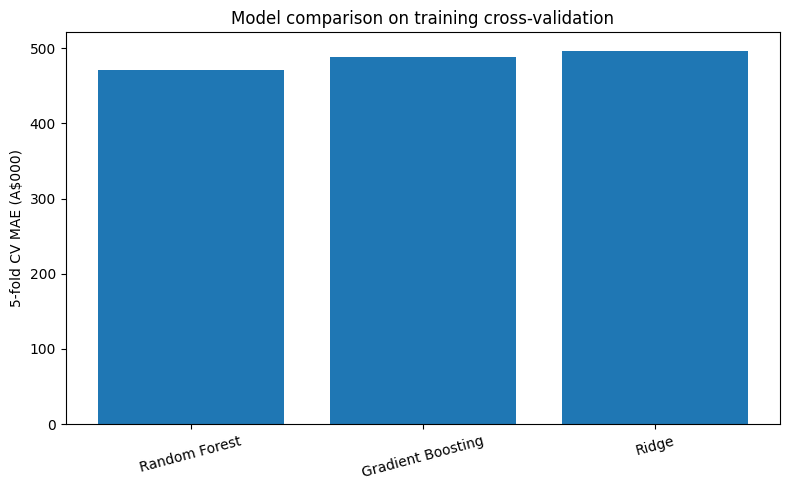

,depth,train_mae,cv_mae
0,2,430921.397213,526046.633004
1,4,298218.569947,483343.781721
2,6,271716.387417,474754.779989
3,None,266654.527521,476641.807068


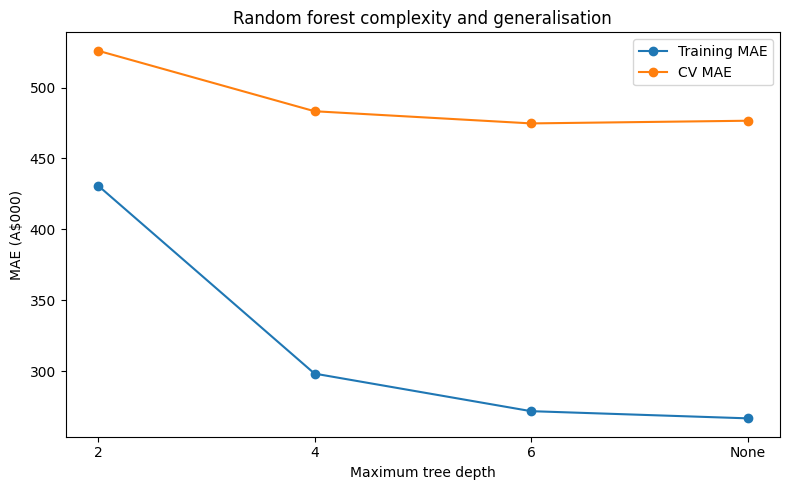

In [10]:
plt.figure(figsize=(8,5))
plt.bar(metrics['Model'],metrics['CV_MAE']/1000)
plt.ylabel('5-fold CV MAE (A$000)'); plt.title('Model comparison on training cross-validation')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

rf_depth=[]
for depth in [2,4,6,None]:
    pipe=Pipeline([('prep',prep_tree),('model',RandomForestRegressor(n_estimators=120,max_depth=depth,min_samples_leaf=2,random_state=42,n_jobs=1))])
    sc=cross_validate(pipe,X_train,y_train,cv=cv_splits,scoring='neg_mean_absolute_error',return_train_score=True,n_jobs=1)
    rf_depth.append({'depth':'None' if depth is None else str(depth),'train_mae':-sc['train_score'].mean(),'cv_mae':-sc['test_score'].mean()})
rf_depth=pd.DataFrame(rf_depth)
display(rf_depth)
plt.figure(figsize=(8,5))
plt.plot(rf_depth['depth'],rf_depth['train_mae']/1000,marker='o',label='Training MAE')
plt.plot(rf_depth['depth'],rf_depth['cv_mae']/1000,marker='o',label='CV MAE')
plt.xlabel('Maximum tree depth'); plt.ylabel('MAE (A$000)'); plt.title('Random forest complexity and generalisation')
plt.legend(); plt.tight_layout(); plt.show()

The training/validation gap is important. Ridge shows the smallest gap and therefore the lowest variance, but its linear form limits flexibility. The ensembles achieve lower training error; the random forest shows a larger train-versus-CV gap, which indicates some overfitting pressure. Cross-validation MAE, rather than the test result, is used to select the final model so the held-out test remains an unbiased final check.

Held-out test MAE:  A$509,178
Held-out test RMSE: A$914,559
Held-out test R²:   0.803


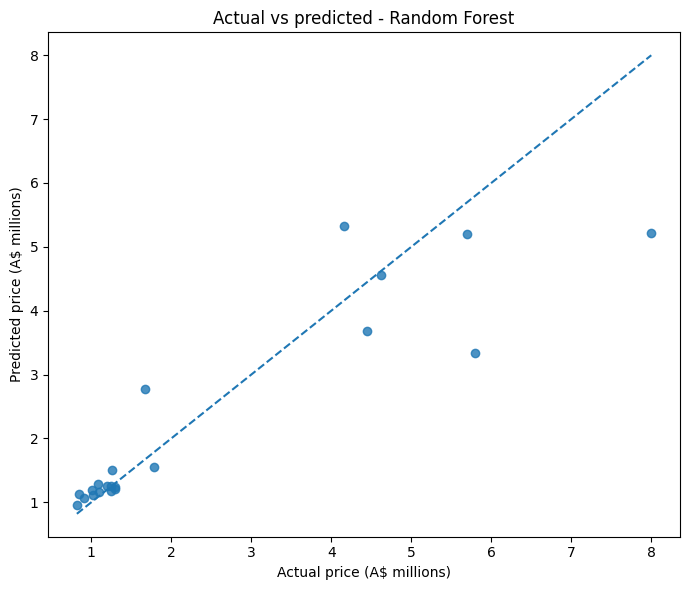

In [11]:
best_model.fit(X_train,y_train)
pred_best=best_model.predict(X_test)
print('Held-out test MAE:  A${:,.0f}'.format(mean_absolute_error(y_test,pred_best)))
print('Held-out test RMSE: A${:,.0f}'.format(mean_squared_error(y_test,pred_best)**0.5))
print('Held-out test R²:   {:.3f}'.format(r2_score(y_test,pred_best)))

plt.figure(figsize=(7,6))
plt.scatter(y_test/1e6,pred_best/1e6,alpha=.8)
lo=min(y_test.min(),pred_best.min())/1e6; hi=max(y_test.max(),pred_best.max())/1e6
plt.plot([lo,hi],[lo,hi],'--')
plt.xlabel('Actual price (A$ millions)'); plt.ylabel('Predicted price (A$ millions)')
plt.title('Actual vs predicted - '+best_name); plt.tight_layout(); plt.show()

In [12]:
prep=best_model.named_steps['prep']
feat_names=prep.get_feature_names_out()
mdl=best_model.named_steps['model']
importance=np.abs(mdl.coef_) if hasattr(mdl,'coef_') else mdl.feature_importances_
importance=pd.DataFrame({'feature':feat_names,'importance':importance}).sort_values('importance',ascending=False)
display(importance.head(12))

,feature,importance
10,cat__suburb_Bondi Beach,0.606195
0,num__bedrooms,0.091159
5,num__sale_month,0.073525
2,num__parking,0.049830
6,num__bed_bath_total,0.045293
8,num__parking_per_bed,0.021258
14,cat__property_type_Other,0.019895
7,num__land_per_bed,0.017139
3,num__land_size_m2,0.017067
16,cat__sale_quarter_1,0.013815


The selected model strongly relies on the Bondi Beach location indicator, while bedrooms, sale timing, parking and combined dwelling capacity also contribute. This broadly supports the initial expectation that **location and size-related features** are central. Property type is useful, but because the sample composition differs by suburb, some type information is partly absorbed by the suburb feature.

## Part 4 - Investigating prediction failures

Large residuals are more informative than the average metric because they reveal which properties are not well represented by the training data. I examine the five largest absolute errors on the untouched test set.

In [13]:
err=meta_test[['suburb','address','sale_price','bedrooms','bathrooms','parking','land_size_m2','property_type','sale_date']].copy()
err['predicted_price']=pred_best
err['absolute_error']=(err['sale_price']-err['predicted_price']).abs()
err['percentage_error']=100*err['absolute_error']/err['sale_price']
err=err.sort_values('absolute_error',ascending=False).reset_index(drop=True)
display(err.head(5))

,suburb,address,sale_price,bedrooms,bathrooms,parking,land_size_m2,property_type,sale_date,predicted_price,absolute_error,percentage_error
0,Bondi Beach,10 Forest Knoll Avenue,8000000,6,3,3.0,600.0,House,2025-11-08,5.221356e+06,2.778644e+06,34.733050
1,Bondi Beach,29 Sir Thomas Mitchell Road,5800000,3,1,1.0,346.0,House,2021-04-24,3.330239e+06,2.469761e+06,42.582087
2,Bondi Beach,9 Cox Avenue,4153000,4,2,NaN,220.7,House,2026-05-09,5.319484e+06,1.166484e+06,28.087732
3,Bondi Beach,4/22-28 O'Brien Street,1670000,2,2,1.0,NaN,Other,2026-05-13,2.770971e+06,1.100971e+06,65.926403
4,Bondi Beach,160 Hall Street,4450000,3,3,1.0,374.0,House,2024-11-09,3.688567e+06,7.614327e+05,17.110848


The five largest errors are concentrated in Bondi Beach. Two major under-predictions are unusually expensive houses, while one attached/“Other” dwelling is substantially over-predicted. The structured features cannot represent ocean views, architectural quality, renovation standard, frontage, exact micro-location, zoning/development potential or sale conditions. These cases show why automated estimates should be treated cautiously for prestige homes, atypical dwellings and properties whose value depends on qualitative attributes missing from the dataset.

## Part 5 - Machine learning, LLM and human-style judgement

**Selection rule.** The 10 comparison properties are chosen deterministically from the untouched test set. Test rows are grouped by suburb and sorted alphabetically by address; the first 4 Bondi Beach rows, first 3 Parramatta rows, and first 3 Blacktown rows are selected. This rule uses only `suburb` and `address` and does not use sale price, prediction error, or LLM outcome.

**LLM reproducibility.** The exact feature-only prompt template and the property-by-property inputs/recorded numeric outputs are included in `part5_llm_prompt_output_log.md`. The notebook reads the recorded estimates from `part5_llm_estimates_recorded.csv` instead of hiding them in code.

**Blinding limitation.** The original integrated GenAI workflow did not preserve a complete raw chat transcript or a provably blinded session record. I therefore do not claim that the historical LLM estimates can be retrospectively proven to have been generated before the assistant had access to actual prices. `part5_blinded_inputs.csv` and `PART5_BLINDED_RERUN_CHECKLIST.txt` are included so the 10 prompts can be rerun in a fresh LLM session before any `sale_price` values are revealed.


In [14]:
sel=[]
for s,n in [('Bondi Beach',4),('Parramatta',3),('Blacktown',3)]:
    sel.append(err[err.suburb==s].sort_values('address').head(n))
comp=pd.concat(sel,ignore_index=True)

llm_log = pd.read_csv('part5_llm_estimates_recorded.csv')
llm_map = dict(zip(llm_log['address'], llm_log['llm_estimate']))

def manual_estimate(row):
    exact=meta_train[(meta_train['suburb']==row['suburb']) & (meta_train['property_type']==row['property_type'])]
    grp=exact if len(exact)>=3 else meta_train[meta_train['suburb']==row['suburb']]
    base=float(grp['sale_price'].median())
    factor=1 + 0.07*(row['bedrooms']-grp['bedrooms'].median()) + 0.05*(row['bathrooms']-grp['bathrooms'].median())
    if pd.notna(row['parking']) and grp['parking'].notna().any(): factor += 0.02*(row['parking']-grp['parking'].median())
    if pd.notna(row['land_size_m2']) and grp['land_size_m2'].notna().sum()>=3:
        lm=grp['land_size_m2'].median(); factor += np.clip((row['land_size_m2']-lm)/lm*0.08,-0.12,0.15)
    return round(base*factor/50000)*50000

comp['ml_prediction']=best_model.predict(engineer(comp)[features])
comp['llm_estimate']=comp['address'].map(llm_map)
comp['manual_estimate']=comp.apply(manual_estimate,axis=1)
for c in ['ml_prediction','llm_estimate','manual_estimate']:
    comp[c+'_abs_error']=(comp['sale_price']-comp[c]).abs()
display(comp[['suburb','address','sale_price','ml_prediction','llm_estimate','manual_estimate']])

comparison=pd.DataFrame({
    'Approach':['ML model','LLM estimate','Manual baseline'],
    'MAE':[comp['ml_prediction_abs_error'].mean(),comp['llm_estimate_abs_error'].mean(),comp['manual_estimate_abs_error'].mean()],
    'RMSE':[(np.mean((comp.sale_price-comp.ml_prediction)**2))**0.5,
            (np.mean((comp.sale_price-comp.llm_estimate)**2))**0.5,
            (np.mean((comp.sale_price-comp.manual_estimate)**2))**0.5]})
display(comparison)


,suburb,address,sale_price,ml_prediction,llm_estimate,manual_estimate
0,Bondi Beach,10 Forest Knoll Avenue,8000000,5.221356e+06,6200000,5450000
1,Bondi Beach,160 Hall Street,4450000,3.688567e+06,4100000,4150000
2,Bondi Beach,29 Sir Thomas Mitchell Road,5800000,3.330239e+06,4400000,3700000
3,Bondi Beach,4/22-28 O'Brien Street,1670000,2.770971e+06,1800000,1500000
4,Parramatta,1/77-79 Thomas Street,1300000,1.232309e+06,1350000,1250000
5,Parramatta,10/43 Pemberton Street,1101500,1.168630e+06,1150000,1150000
6,Parramatta,2/25-29 O'Connell Street,851000,1.127324e+06,950000,1000000
7,Blacktown,1 Tara Road,820000,9.518699e+05,900000,950000
8,Blacktown,12 Siebel Street,1080000,1.288750e+06,1350000,1250000
9,Blacktown,24 Twilight Crescent,1024000,1.107587e+06,1100000,1150000


,Approach,MAE,RMSE
0,ML model,794615.968865,1.255623e+06
1,LLM estimate,430350.000000,7.375045e+05
2,Manual baseline,579350.000000,1.054520e+06


On this small 10-property comparison, the LLM/manual baselines can outperform the fitted model because the ML model struggles with a few unusual Bondi Beach houses. This does **not** establish that an LLM is generally superior: the comparison is very small, the LLM has broad prior knowledge but no guarantee of current market accuracy, and the manual baseline is based on hand-designed comparable adjustments. ML remains reproducible and consistent, while human/LLM judgement can add contextual reasoning when structured variables omit important qualitative information.

## Part 6 - Deployment and reflection

The final fitted pipeline is exported with `joblib` and used by the supplied `app.py` Gradio application. The app supports both a single-property form and batch CSV upload. Preprocessing and feature engineering are reproduced at prediction time, so the user does not need to manually encode categories.

In [15]:
joblib.dump({'model':best_model,'features':features,'best_model_name':best_name}, ROOT/'best_model.joblib')
print('Saved model bundle:', ROOT/'best_model.joblib')

Saved model bundle: best_model.joblib


### Critical reflection

The most difficult part was not fitting models but constructing a defensible dataset and keeping the evaluation honest. Manual listing data contained missing fields, inconsistent property labels and a non-random mix of sales. A larger sample with floor area, exact coordinates, distance to transport/coast, renovation quality, school catchments, views, zoning, property age and text descriptions would likely reduce the largest errors. Image and text features could also capture prestige characteristics that simple tabular fields miss.

The deployment trade-off is clear: a small tree ensemble is fast and easy to serve, but practical valuation accuracy is limited by data quality more than computational power. Automated property valuation also creates fairness and transparency concerns. Historical prices can encode neighbourhood-level inequalities, and model predictions may be interpreted as objective even when important attributes are missing. The application therefore presents the output as decision support rather than a professional valuation.

### GenAI acknowledgement

ChatGPT (OpenAI, GPT-5.6 Sol) was used to help plan the workflow, draft and debug Python code, structure the report, and provide the feature-only LLM valuation comparison. All dataset records were taken from the cited public sold-listing pages. The final submission should be critically reviewed by the student, who remains responsible for the accuracy of the analysis and for explaining the modelling decisions in any follow-up discussion.

## References

- Realestate.com.au sold-property listings for Bondi Beach, Parramatta and Blacktown (source URLs are stored per row in `sydney_housing_sold_105.csv`).
- Scikit-learn documentation: preprocessing pipelines, Ridge, RandomForestRegressor, GradientBoostingRegressor, GridSearchCV and regression metrics.
- Gradio documentation: Blocks interface and input/output components used for the deployment prototype.